# EnergIA · Entrenamiento de los modelos
### Predicción semanal del consumo por aparato y detección de anomalías

**Datos:** `lecturas_2s_1.csv`, lecturas cada 2 segundos de cinco nodos, uno por electrodoméstico:

| Nodo | Electrodoméstico |
|---|---|
| nodo_1 | Nevera1 |
| nodo_2 | Nevera2 |
| nodo_3 | Router |
| nodo_4 | PC |
| nodo_5 | TVyDeco (televisor y decodificador) |

**Archivos que genera** (en `modelos_EnergIA.zip`):

| Archivo | Contenido |
|---|---|
| `modelo_prediccion.joblib` | Energía (kWh) de cada aparato en cada hora de los próximos 7 días, en bloques de 24 horas encadenados |
| `modelo_anomalias.joblib` | Un Isolation Forest por aparato con su umbral |
| `modelos_info.json` | Versiones, variables, periodo de los datos, métricas y umbrales; el backend lo usa para cargar los modelos |
| `variables.py` | Cálculo de las variables, compartido con el backend |

**Ejecución en Google Colab:** subir `lecturas_2s_1.csv` a Google Drive, abrir el notebook, revisar la celda de Configuración y ejecutar todas las celdas. Los archivos del zip se copian en la carpeta `modelos/` del backend.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Configuración
- `RUTA_DRIVE`: ubicación del archivo de datos en Google Drive.
- `TARIFA_COP_KWH`: valor del kWh en pesos; solo se usa para mostrar costos.

In [ ]:
# Parámetros
RUTA_DRIVE     = '/content/drive/MyDrive/Datos/lecturas_2s.csv'   # ubicación del archivo en Google Drive
TARIFA_COP_KWH = 850
SEMILLA        = 0

# Rango de medición del PZEM-004T v3
RANGO = {'voltaje': (80, 260), 'corriente': (0, 100), 'potencia': (0, 23000)}

# Librerías
import warnings; warnings.filterwarnings('ignore')
import json, os, shutil, time
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import sklearn, joblib
from IPython.display import display, Markdown

pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
pd.set_option('display.max_columns', 30)

# Estilo de las gráficas
ORDEN = ['Nevera1', 'Nevera2', 'TVyDeco', 'PC', 'Router']
COLOR = {'Nevera1': '#2a78d6', 'Nevera2': '#eb6834', 'TVyDeco': '#1baf7a', 'PC': '#6250d6', 'Router': '#e34948'}
GRIS, TINTA, TINTA2 = '#d9d8d4', '#0b0b0b', '#52514e'
plt.rcParams.update({
    'figure.figsize': (12, 4.5), 'figure.dpi': 110, 'figure.facecolor': 'white',
    'axes.facecolor': 'white', 'axes.edgecolor': GRIS, 'axes.labelcolor': TINTA2,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.titlecolor': TINTA, 'axes.labelsize': 10.5,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#ecebe8', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'xtick.color': TINTA2, 'ytick.color': TINTA2, 'xtick.labelsize': 9.5, 'ytick.labelsize': 9.5,
    'legend.frameon': False, 'legend.fontsize': 10, 'lines.linewidth': 2,
})
fmt_cop = lambda x: f'${x:,.0f}'.replace(',', '.')

print(f'scikit-learn {sklearn.__version__} · pandas {pd.__version__} · numpy {np.__version__}')
print('IMPORTANTE: instala esta misma versión de scikit-learn en la Raspberry:')
print(f'  /home/luisool/venv/bin/pip install scikit-learn=={sklearn.__version__}')

scikit-learn 1.6.1 · pandas 2.2.3 · numpy 2.4.6
IMPORTANTE: instala esta misma versión de scikit-learn en la Raspberry:
  /home/luisool/venv/bin/pip install scikit-learn==1.6.1


## 2. Variables de los modelos (`variables.py`)
Esta celda escribe `variables.py`, el mismo archivo que usa el backend, de modo que los modelos reciben en la Raspberry las variables con las que se entrenaron.

In [ ]:
%%writefile variables.py
"""
variables.py · Variables (features) de los modelos de EnergIA.

Este mismo archivo lo usan el notebook de entrenamiento (Colab) y el backend
(Raspberry). Si el backend calcula las variables de otra forma, el modelo
predice valores sin sentido sin dar ningún error; por eso el cálculo vive en
un solo lugar.

Entrada común: una tabla HORARIA con una fila por aparato y hora:
    fecha_hora  (inicio de la hora, hora de Colombia, sin zona horaria)
    aparato     (Nevera1, Nevera2, Router, PC, TVyDeco)
    kwh         (energía consumida en esa hora)
"""

import numpy as np
import pandas as pd

APARATOS = ['Nevera1', 'Nevera2', 'Router', 'PC', 'TVyDeco']
NODO_A_APARATO = {'nodo_1': 'Nevera1', 'nodo_2': 'Nevera2', 'nodo_3': 'Router',
                  'nodo_4': 'PC', 'nodo_5': 'TVyDeco'}

# Festivos de Colombia (Ley Emiliani) 2026 y 2027
FESTIVOS = {pd.Timestamp(d).date() for d in [
    '2026-01-01', '2026-01-12', '2026-03-23', '2026-04-02', '2026-04-03', '2026-05-01',
    '2026-05-18', '2026-06-08', '2026-06-15', '2026-06-29', '2026-07-20', '2026-08-07',
    '2026-08-17', '2026-10-12', '2026-11-02', '2026-11-16', '2026-12-08', '2026-12-25',
    '2027-01-01', '2027-01-11', '2027-03-22', '2027-03-25', '2027-03-26', '2027-05-01',
    '2027-05-10', '2027-05-31', '2027-06-07', '2027-07-05', '2027-07-20', '2027-08-07',
    '2027-08-16', '2027-10-18', '2027-11-01', '2027-11-15', '2027-12-08', '2027-12-25',
]}

# Variables del modelo de predicción, en este orden exacto
VARIABLES_PREDICCION = [
    'hora_sin', 'hora_cos', 'dia_sin', 'dia_cos', 'fin_de_semana_o_festivo',
    'lag24', 'lag48', 'lag168', 'media_dia_anterior', 'media_misma_hora_7d',
    *[f'es_{a}' for a in APARATOS],
]

# Variables del detector de anomalías (por aparato), en este orden exacto
VARIABLES_ANOMALIAS = ['kwh', 'pct_encendido', 'arranques', 'p_encendido_media', 'hora_sin', 'hora_cos']

UMBRAL_ENCENDIDO_W = 2.4   # 0,02 A x 120 V: el mismo umbral de los nodos


def calendario(fechas: pd.Series) -> pd.DataFrame:
    """Hora y día codificados de forma cíclica (las 23 h quedan cerca de las 0 h)."""
    f = pd.to_datetime(fechas)
    hora = f.dt.hour
    dia = f.dt.dayofweek
    festivo = f.dt.date.isin(FESTIVOS)
    return pd.DataFrame({
        'hora_sin': np.sin(2 * np.pi * hora / 24),
        'hora_cos': np.cos(2 * np.pi * hora / 24),
        'dia_sin': np.sin(2 * np.pi * dia / 7),
        'dia_cos': np.cos(2 * np.pi * dia / 7),
        'fin_de_semana_o_festivo': ((dia >= 5) | festivo).astype(int),
    }, index=fechas.index)


def variables_prediccion(horaria: pd.DataFrame) -> pd.DataFrame:
    """Agrega las variables de predicción a la tabla horaria.

    Todas las variables de consumo miran al menos 24 horas atrás: así, con los
    datos hasta "ahora", se pueden predecir de una vez las 24 horas siguientes.
    Las filas sin historia suficiente quedan con NaN (se descartan al entrenar).
    """
    h = horaria.sort_values(['aparato', 'fecha_hora']).copy()
    # Rejilla completa de horas por aparato, para que "24 filas atrás" sea "24 horas atrás"
    partes = []
    for a, g in h.groupby('aparato', sort=False):
        horas = pd.date_range(g.fecha_hora.min(), g.fecha_hora.max(), freq='h')
        g = g.set_index('fecha_hora').reindex(horas)
        g.index.name = 'fecha_hora'
        g['aparato'] = a
        partes.append(g.reset_index())
    h = pd.concat(partes, ignore_index=True)

    k = h.groupby('aparato', sort=False)['kwh']
    for lag in (24, 48, 168):
        h[f'lag{lag}'] = k.shift(lag)
    # Promedio de las 24 horas que terminan 24 horas antes
    h['media_dia_anterior'] = k.transform(lambda s: s.shift(24).rolling(24, min_periods=18).mean())
    # Promedio de la misma hora en los 7 días anteriores
    h['media_misma_hora_7d'] = sum(k.shift(24 * d) for d in range(1, 8)) / 7

    h = pd.concat([h, calendario(h['fecha_hora'])], axis=1)
    for a in APARATOS:
        h[f'es_{a}'] = (h['aparato'] == a).astype(int)
    return h


HORIZONTE_HORAS = 168      # predicción semanal: los próximos 7 días
DIAS_HISTORIA = 9          # historia que necesita cada bloque (lag168 + promedio de 7 días)


def prediccion_recursiva(modelo, historia: pd.DataFrame, inicio, horas: int = HORIZONTE_HORAS) -> pd.DataFrame:
    """Predice `horas` horas desde `inicio` (inclusive) por bloques de 24 horas.

    Cada bloque se predice con las variables de la historia; luego sus predicciones
    se agregan a la historia como si fueran consumo medido y se calcula el bloque
    siguiente. Así el modelo de 24 horas llega a los 7 días.

    historia: tabla horaria (fecha_hora, aparato, kwh) con datos ANTERIORES a `inicio`.
    Devuelve: fecha_hora, aparato, kwh_pred y dia_horizonte (1 = primeras 24 horas).
    """
    inicio = pd.Timestamp(inicio)
    h = historia.loc[(historia.fecha_hora < inicio) &
                     (historia.fecha_hora >= inicio - pd.Timedelta(days=DIAS_HISTORIA)),
                     ['fecha_hora', 'aparato', 'kwh']]
    bloques = []
    for desde in range(0, horas, 24):
        ini = inicio + pd.Timedelta(hours=desde)
        n = min(24, horas - desde)
        futuro = pd.DataFrame([(ini + pd.Timedelta(hours=k), a, np.nan) for a in APARATOS for k in range(n)],
                              columns=['fecha_hora', 'aparato', 'kwh'])
        t = variables_prediccion(pd.concat([h, futuro], ignore_index=True))
        t = t[(t.fecha_hora >= ini) & (t.fecha_hora < ini + pd.Timedelta(hours=n))]
        pred = np.clip(modelo.predict(t[VARIABLES_PREDICCION]), 0, None)
        bloque = t[['fecha_hora', 'aparato']].assign(kwh_pred=pred, dia_horizonte=desde // 24 + 1)
        bloques.append(bloque)
        h = pd.concat([h, bloque.rename(columns={'kwh_pred': 'kwh'})[['fecha_hora', 'aparato', 'kwh']]],
                      ignore_index=True)
    return pd.concat(bloques, ignore_index=True)


def tabla_horaria_desde_minutos(minutos: pd.DataFrame) -> pd.DataFrame:
    """De una tabla por minuto (fecha_hora, aparato, potencia en W, voltaje)
    a la tabla horaria con las variables que usan los dos modelos."""
    m = minutos.copy()
    m['hora_ini'] = m['fecha_hora'].dt.floor('h')
    m['encendido'] = m['potencia'] >= UMBRAL_ENCENDIDO_W
    m = m.sort_values(['aparato', 'fecha_hora'])
    m['arranque'] = m.groupby('aparato')['encendido'].transform(lambda s: s & ~s.shift(1, fill_value=False))
    g = m.groupby(['aparato', 'hora_ini'])
    hor = pd.DataFrame({
        'kwh': g['potencia'].sum() / 60 / 1000,          # W·min -> kWh
        'minutos': g['potencia'].size(),
        'pct_encendido': g['encendido'].mean() * 100,
        'arranques': g['arranque'].sum(),
        'p_encendido_media': g.apply(lambda x: x.loc[x.encendido, 'potencia'].mean() if x.encendido.any() else 0.0),
        'voltaje_medio': g['voltaje'].mean(),
    }).reset_index().rename(columns={'hora_ini': 'fecha_hora'})
    return hor


def variables_anomalias(horaria: pd.DataFrame) -> pd.DataFrame:
    """Variables del detector de anomalías: una fila por aparato y hora."""
    h = horaria.copy()
    cal = calendario(h['fecha_hora'])
    h['hora_sin'], h['hora_cos'] = cal['hora_sin'], cal['hora_cos']
    return h

Writing variables.py


In [ ]:
import importlib, variables
importlib.reload(variables)
from variables import (APARATOS, NODO_A_APARATO, VARIABLES_PREDICCION, VARIABLES_ANOMALIAS,
                       variables_prediccion, tabla_horaria_desde_minutos, variables_anomalias)
print('Variables de predicción:', VARIABLES_PREDICCION)
print('Variables de anomalías: ', VARIABLES_ANOMALIAS)

Variables de predicción: ['hora_sin', 'hora_cos', 'dia_sin', 'dia_cos', 'fin_de_semana_o_festivo', 'lag24', 'lag48', 'lag168', 'media_dia_anterior', 'media_misma_hora_7d', 'es_Nevera1', 'es_Nevera2', 'es_Router', 'es_PC', 'es_TVyDeco']
Variables de anomalías:  ['kwh', 'pct_encendido', 'arranques', 'p_encendido_media', 'hora_sin', 'hora_cos']


## 3. Carga de los datos

In [ ]:
RUTA = 'lecturas_2s_1.csv'
try:
    from google.colab import drive
    drive.mount('/content/drive')
    RUTA = RUTA_DRIVE
except ImportError:
    print('No estás en Colab: se usa la ruta local', RUTA)

inicio_carga = time.time()
df = pd.read_csv(RUTA, usecols=['fecha_hora_local', 'nodo', 'voltaje', 'corriente', 'potencia'],
                 dtype={'nodo': 'category'})
df['fecha_hora_local'] = pd.to_datetime(df['fecha_hora_local'], format='mixed')
df['aparato'] = df['nodo'].map(NODO_A_APARATO).astype('category')
print(f'{len(df):,} lecturas cargadas en {time.time() - inicio_carga:.0f} s')
print('Periodo:', df.fecha_hora_local.min(), '→', df.fecha_hora_local.max())
display(df.groupby('aparato', observed=True).size().rename('lecturas').to_frame())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
3,677,417 lecturas cargadas en 11 s
Periodo: 2026-09-29 14:00:00 → 2026-10-26 23:59:59.415000


,lecturas
aparato,
Nevera1,658326
Nevera2,468463
Router,1125928
PC,275881
TVyDeco,1148819


## 4. Preparación

### 4.1 Lecturas fuera del rango del sensor
El PZEM-004T v3 mide de 80 a 260 V, de 0 a 100 A y de 0 a 23 kW; las lecturas por fuera son errores del sensor y se eliminan.

In [ ]:
fuera = np.zeros(len(df), bool)
for var, (lo, hi) in RANGO.items():
    fuera |= ~df[var].between(lo, hi).to_numpy()
print(f'Lecturas fuera de rango eliminadas: {fuera.sum()}')
display(df.loc[fuera, ['fecha_hora_local', 'aparato', 'voltaje', 'corriente', 'potencia']])
df = df.loc[~fuera]

Lecturas fuera de rango eliminadas: 6


,fecha_hora_local,aparato,voltaje,corriente,potencia
1060121,2026-10-07 11:04:49.964,PC,"2,252.800","12,737.280","6,846,258.500"
2170078,2026-10-15 15:06:13.006,PC,77.500,0.021,1.000
2170079,2026-10-15 15:06:13.269,Router,77.400,0.333,19.100
2170080,2026-10-15 15:06:13.644,Nevera1,74.700,1.281,92.900
2170083,2026-10-15 15:06:15.012,PC,79.500,0.020,1.000
2170084,2026-10-15 15:06:15.277,Router,79.500,0.331,19.200


### 4.2 De lecturas cada 2 segundos a minutos
Se promedia por minuto y por aparato. Los nodos no envían lecturas con el aparato apagado (menos de 0,02 A), así que se completa la rejilla de minutos del periodo y los minutos sin lecturas se registran como 0 W. Sin este paso, el promedio solo contaría los periodos encendidos.

El voltaje de un minuto sin lectura se toma del promedio de los otros nodos en ese minuto, porque todos comparten la red.

In [ ]:
df['minuto'] = df.fecha_hora_local.dt.floor('min')
m = (df.groupby(['aparato', 'minuto'], observed=True)[['voltaje', 'corriente', 'potencia']]
       .mean().reset_index())

minutos = pd.date_range(m.minuto.min(), m.minuto.max(), freq='min')
rejilla = pd.MultiIndex.from_product([APARATOS, minutos], names=['aparato', 'minuto'])
m = m.set_index(['aparato', 'minuto']).reindex(rejilla).reset_index()
m['potencia'] = m['potencia'].fillna(0.0)
m['corriente'] = m['corriente'].fillna(0.0)
v_red = m.groupby('minuto')['voltaje'].transform('mean')
m['voltaje'] = m['voltaje'].fillna(v_red).interpolate(limit_direction='both')
m = m.rename(columns={'minuto': 'fecha_hora'})
del df

print(f'{len(m):,} filas por minuto ({len(minutos):,} minutos x {len(APARATOS)} aparatos)')
resumen = m.groupby('aparato').agg(potencia_media_W=('potencia', 'mean'),
                                   pct_encendido=('potencia', lambda p: 100 * (p >= 2.4).mean()))
resumen['kWh_mes'] = resumen.potencia_media_W * 720 / 1000
resumen['COP_mes'] = resumen.kWh_mes * TARIFA_COP_KWH
display(resumen.reindex(ORDEN).round(1))
print(f'TOTAL: {resumen.kWh_mes.sum():.0f} kWh/mes ≈ {fmt_cop(resumen.COP_mes.sum())} COP/mes')

197,400 filas por minuto (39,480 minutos x 5 aparatos)


,potencia_media_W,pct_encendido,kWh_mes,COP_mes
aparato,,,,
Nevera1,39.900,47.500,28.700,"24,406.300"
Nevera2,54.800,42.000,39.500,"33,551.400"
TVyDeco,27.000,99.600,19.400,"16,525.600"
PC,17.900,25.100,12.900,"10,938.200"
Router,18.900,100.000,13.600,"11,564.200"


TOTAL: 114 kWh/mes ≈ $96.986 COP/mes


### 4.3 Tabla horaria
Para cada aparato y hora se calculan la energía (kWh), el porcentaje del tiempo encendido, el número de arranques, la potencia media encendido y el voltaje medio. Se descartan la primera y la última hora si están incompletas.

3,290 filas horarias · 658 horas · 28 días


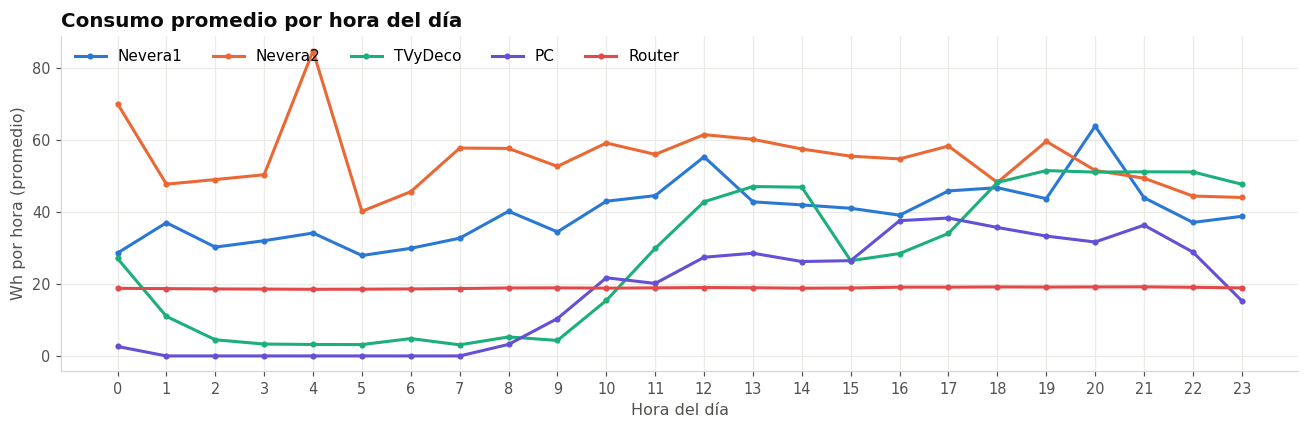

In [ ]:
horaria = tabla_horaria_desde_minutos(m)
horaria = horaria[horaria.minutos == 60].drop(columns='minutos').reset_index(drop=True)
print(f'{len(horaria):,} filas horarias · {horaria.fecha_hora.nunique():,} horas · '
      f'{horaria.fecha_hora.dt.normalize().nunique()} días')

perfil = horaria.assign(hora=horaria.fecha_hora.dt.hour).pivot_table(index='hora', columns='aparato', values='kwh')
fig, ax = plt.subplots(figsize=(12, 4))
for a in ORDEN:
    ax.plot(perfil.index, perfil[a] * 1000, color=COLOR[a], marker='o', ms=3, label=a)
ax.set_xticks(range(24)); ax.set_xlabel('Hora del día'); ax.set_ylabel('Wh por hora (promedio)')
ax.legend(ncol=5, loc='upper left'); ax.set_title('Consumo promedio por hora del día')
plt.tight_layout(); plt.show()

## 5. Modelo de predicción semanal

### 5.1 Variables y estrategia
| Variable | Descripción |
|---|---|
| `hora_sin`, `hora_cos` | Hora del día en codificación cíclica |
| `dia_sin`, `dia_cos` | Día de la semana en codificación cíclica |
| `fin_de_semana_o_festivo` | 1 si es sábado, domingo o festivo de Colombia |
| `lag24`, `lag48`, `lag168` | Consumo de la misma hora hace 1 día, 2 días y 1 semana |
| `media_dia_anterior` | Promedio de las 24 horas que terminan un día antes |
| `media_misma_hora_7d` | Promedio de la misma hora en los 7 días anteriores |
| `es_Nevera1` … `es_TVyDeco` | Aparato al que corresponde la fila |

**Objetivo:** energía de la hora (kWh) de cada aparato.

**Estrategia recursiva.** Ninguna variable usa las últimas 24 horas, así que el modelo predice de una vez las 24 horas siguientes. Para la semana, esas predicciones se agregan a la historia y se predicen las 24 horas siguientes, hasta completar 7 días (`prediccion_recursiva` en `variables.py`). El error crece con el horizonte.

In [ ]:
from variables import prediccion_recursiva, HORIZONTE_HORAS

datos = variables_prediccion(horaria[['fecha_hora', 'aparato', 'kwh']])
datos = datos.dropna(subset=VARIABLES_PREDICCION + ['kwh']).reset_index(drop=True)

# Orígenes: medianoches desde las que se predice una semana completa.
# Cada origen necesita al menos MIN_DIAS_ENTRENAMIENTO días de filas válidas antes y 7 días medidos después.
MIN_DIAS_ENTRENAMIENTO = 7
primera_valida = datos.fecha_hora.min()
fin_datos = horaria.fecha_hora.max() + pd.Timedelta(hours=1)
ORIGENES = [o for o in pd.date_range(primera_valida.normalize() + pd.Timedelta(days=1), fin_datos, freq='D')
            if o - primera_valida >= pd.Timedelta(days=MIN_DIAS_ENTRENAMIENTO)
            and o + pd.Timedelta(hours=HORIZONTE_HORAS) <= fin_datos]
ORIGEN_PRUEBA = ORIGENES[-1]   # última semana completa (semana de prueba)
print(f'Filas con variables completas: {len(datos):,} (desde {primera_valida:%d-%b %H:%M})')
print(f'{len(ORIGENES)} orígenes de evaluación: {ORIGENES[0]:%d-%b} a {ORIGENES[-1]:%d-%b}')
print(f'Semana de prueba: {ORIGEN_PRUEBA:%d-%b} a {ORIGEN_PRUEBA + pd.Timedelta(days=6):%d-%b}')

Filas con variables completas: 2,450 (desde 06-Oct 14:00)
7 orígenes de evaluación: 14-Oct a 20-Oct
Semana de prueba: 20-Oct a 26-Oct


### 5.2 Evaluación con origen móvil
Desde cada origen se predice la semana siguiente con un modelo entrenado solo con los datos anteriores a ese origen. Se comparan:

| Opción | Descripción |
|---|---|
| Semana pasada (referencia) | Cada hora repite la misma hora de la semana anterior |
| Promedio 7 días (referencia) | Cada hora repite el promedio de esa hora en los 7 días previos al origen |
| Random Forest (recursivo) | Promedio de árboles de decisión |
| HistGradientBoosting (recursivo) | Árboles entrenados en secuencia, cada uno corrige al anterior |

Los hiperparámetros se fijaron con validación temporal (por ejemplo, hojas de al menos 10 horas en el Random Forest).

**Métricas:**
- **MAE (Wh):** error medio por hora y aparato.
- **MAPE semanal (%):** error porcentual de la energía total de la casa en la semana.
- **MAPE diario (%):** error porcentual de la energía de la casa en cada día. Se calcula por día porque las horas con el aparato apagado valen 0.
- **Error por día de horizonte:** MAPE diario del día 1 al día 7 después del origen.

In [ ]:
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

modelos = {
    'Random Forest': RandomForestRegressor(n_estimators=300, min_samples_leaf=10, max_features=0.5,
                                           n_jobs=-1, random_state=SEMILLA),
    'HistGradientBoosting': HistGradientBoostingRegressor(max_iter=200, learning_rate=0.03, max_leaf_nodes=15,
                                                          min_samples_leaf=30, l2_regularization=1.0,
                                                          random_state=SEMILLA),
}
REFERENCIAS = ['Semana pasada', 'Promedio 7 días']
NOMBRES = [*REFERENCIAS, *modelos]
H = horaria[['fecha_hora', 'aparato', 'kwh']]


def referencias(origen):
    semana = pd.date_range(origen, periods=HORIZONTE_HORAS, freq='h')
    antes = H[(H.fecha_hora >= origen - pd.Timedelta(days=7)) & (H.fecha_hora < origen)]
    perfil = antes.assign(hora=antes.fecha_hora.dt.hour).groupby(['aparato', 'hora']).kwh.mean()
    filas = []
    for a in APARATOS:
        previa = antes[antes.aparato == a].set_index('fecha_hora').kwh
        for t in semana:
            filas.append((t, a, previa.get(t - pd.Timedelta(days=7), np.nan), perfil.get((a, t.hour), np.nan)))
    return pd.DataFrame(filas, columns=['fecha_hora', 'aparato', 'pred_Semana pasada', 'pred_Promedio 7 días'])


inicio_eval = time.time()
resultados = []
for origen in ORIGENES:
    real = H[(H.fecha_hora >= origen) & (H.fecha_hora < origen + pd.Timedelta(hours=HORIZONTE_HORAS))]
    r = real.merge(referencias(origen), on=['fecha_hora', 'aparato'])
    entrena = datos[datos.fecha_hora < origen]
    for nombre, mod in modelos.items():
        m_o = sklearn.base.clone(mod).fit(entrena[VARIABLES_PREDICCION], entrena.kwh)
        p = prediccion_recursiva(m_o, H, origen).drop(columns='dia_horizonte').rename(columns={'kwh_pred': f'pred_{nombre}'})
        r = r.merge(p, on=['fecha_hora', 'aparato'])
    r['origen'] = origen
    resultados.append(r)
    print(f'  origen {origen:%d-%b}: {len(entrena):,} filas de entrenamiento')
res = pd.concat(resultados, ignore_index=True)
res['dia'] = res.fecha_hora.dt.normalize()
res['dia_horizonte'] = (res.fecha_hora - res.origen) // pd.Timedelta(days=1) + 1
print(f'Evaluación terminada en {time.time() - inicio_eval:.0f} s')


def mape(real, pred):
    real, pred = np.asarray(real, float), np.asarray(pred, float)
    ok = real > 0
    return 100 * np.mean(np.abs(real[ok] - pred[ok]) / real[ok])


def metricas_de(g, n):
    col = f'pred_{n}'
    casa_dia = g.groupby(['origen', 'dia'])[['kwh', col]].sum()
    casa_sem = g.groupby('origen')[['kwh', col]].sum()
    return {'MAE (Wh)': 1000 * mean_absolute_error(g.kwh, g[col]),
            'MAPE semanal (%)': mape(casa_sem.kwh, casa_sem[col]),
            'MAPE diario (%)': mape(casa_dia.kwh, casa_dia[col])}


resumen_eval = pd.DataFrame({n: metricas_de(res, n) for n in NOMBRES}).T
display(Markdown(f'**Promedio de los {len(ORIGENES)} orígenes (casa completa):**'))
display(resumen_eval.round(2))

# Error por día de horizonte (MAPE diario de la casa)
por_dia = {}
for n in NOMBRES:
    c = res.groupby(['origen', 'dia_horizonte'])[['kwh', f'pred_{n}']].sum().reset_index()
    por_dia[n] = c.groupby('dia_horizonte').apply(lambda x: mape(x.kwh, x[f'pred_{n}']))
por_dia = pd.DataFrame(por_dia)
por_dia.index.name = 'día de horizonte'
display(Markdown('**MAPE diario según el día de horizonte (%):**'))
display(por_dia.round(1).T)

# Se elige el modelo con menor MAE promedio en los orígenes
MEJOR = min(modelos, key=lambda n: resumen_eval.loc[n, 'MAE (Wh)'])
mejor_ref = min(REFERENCIAS, key=lambda n: resumen_eval.loc[n, 'MAE (Wh)'])
mejora = 100 * (1 - resumen_eval.loc[MEJOR, 'MAE (Wh)'] / resumen_eval.loc[mejor_ref, 'MAE (Wh)'])
print(f'Modelo elegido: {MEJOR}')
print(f'Frente a la mejor referencia ({mejor_ref}): {mejora:+.1f} % de error '
      f'({"el modelo es mejor" if mejora > 0 else "la referencia es mejor"}).')

# Métricas por aparato del modelo elegido
por_aparato = pd.DataFrame({a: {'MAE (Wh)': 1000 * mean_absolute_error(g.kwh, g[f'pred_{MEJOR}']),
                                'MAPE semanal (%)': mape(g.groupby('origen').kwh.sum(),
                                                         g.groupby('origen')[f'pred_{MEJOR}'].sum())}
                            for a, g in res.groupby('aparato')}).T.reindex(ORDEN)
display(Markdown(f'**{MEJOR} por aparato:**'))
display(por_aparato.round(2))

  origen 14-Oct: 890 filas de entrenamiento
  origen 15-Oct: 1,010 filas de entrenamiento
  origen 16-Oct: 1,130 filas de entrenamiento
  origen 17-Oct: 1,250 filas de entrenamiento
  origen 18-Oct: 1,370 filas de entrenamiento
  origen 19-Oct: 1,490 filas de entrenamiento
  origen 20-Oct: 1,610 filas de entrenamiento
Evaluación terminada en 18 s


**Promedio de los 7 orígenes (casa completa):**

,MAE (Wh),MAPE semanal (%),MAPE diario (%)
Semana pasada,14.450,1.570,8.250
Promedio 7 días,13.270,1.570,8.930
Random Forest,14.070,7.790,12.930
HistGradientBoosting,15.490,11.210,16.260


**MAPE diario según el día de horizonte (%):**

día de horizonte,1,2,3,4,5,6,7
Semana pasada,7.900,8.200,8.300,8.900,9.100,8.000,7.300
Promedio 7 días,6.700,6.500,8.000,9.100,10.600,10.900,10.700
Random Forest,7.600,8.800,12.300,14.400,16.400,15.200,15.800
HistGradientBoosting,9.000,13.000,14.500,17.800,21.500,18.800,19.300


Modelo elegido: Random Forest
Frente a la mejor referencia (Promedio 7 días): -6.0 % de error (la referencia es mejor).


**Random Forest por aparato:**

,MAE (Wh),MAPE semanal (%)
Nevera1,21.060,14.860
Nevera2,17.040,24.740
TVyDeco,8.010,14.140
PC,23.590,45.010
Router,0.640,1.350


### 5.3 Gráficas de la evaluación

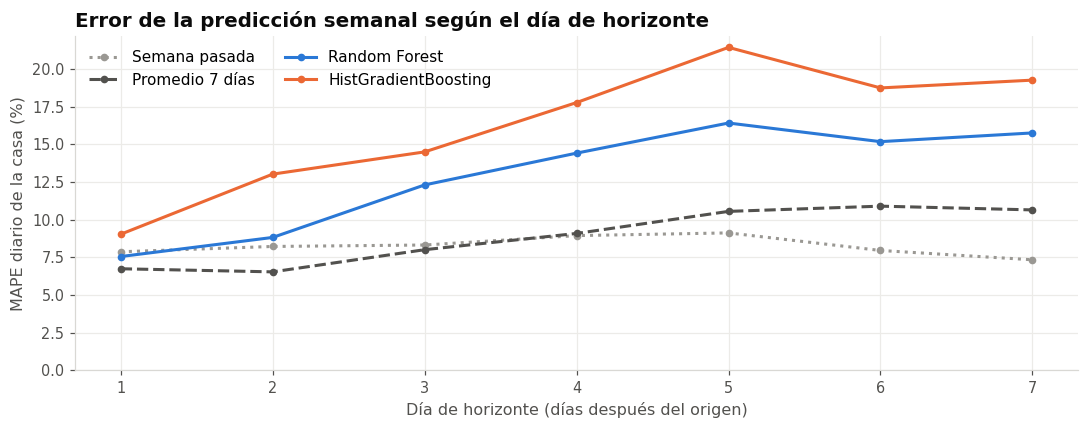

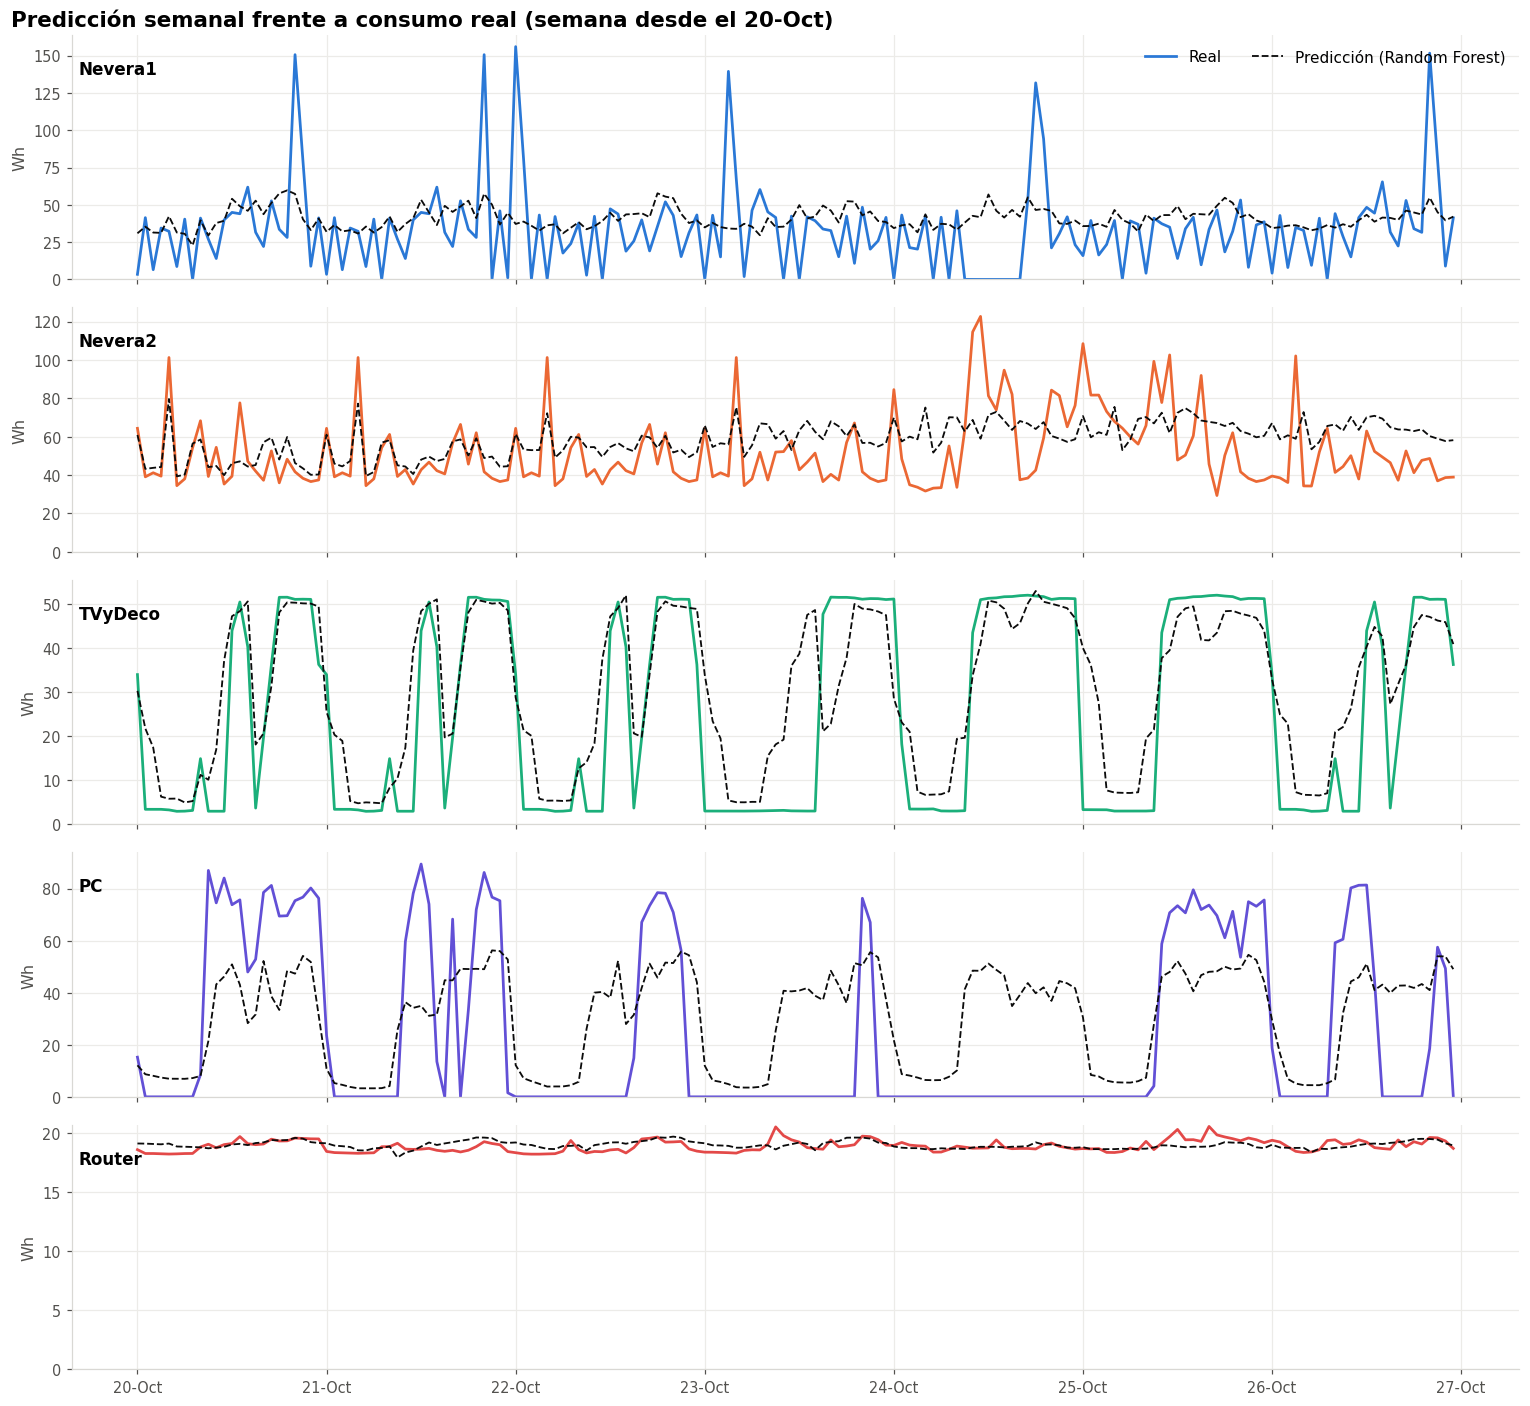

**Semana de prueba, casa completa, por día:**

,real kWh,predicho kWh,error %
dia,,,
2026-10-20,4.180,4.000,4.310
2026-10-21,3.730,4.020,7.650
2026-10-22,3.470,4.170,20.360
2026-10-23,3.100,4.260,37.310
2026-10-24,3.380,4.520,33.890
2026-10-25,4.410,4.640,5.210
2026-10-26,3.620,4.390,21.320


In [ ]:
# Error según el día de horizonte
fig, ax = plt.subplots(figsize=(10, 4))
estilos = {'Semana pasada': ('#9a9893', ':'), 'Promedio 7 días': ('#52514e', '--'),
           'Random Forest': ('#2a78d6', '-'), 'HistGradientBoosting': ('#eb6834', '-')}
for n in NOMBRES:
    color, ls = estilos[n]
    ax.plot(por_dia.index, por_dia[n], color=color, ls=ls, marker='o', ms=4, label=n)
ax.set_xticks(range(1, 8)); ax.set_xlabel('Día de horizonte (días después del origen)')
ax.set_ylabel('MAPE diario de la casa (%)'); ax.set_ylim(bottom=0)
ax.legend(ncol=2); ax.set_title('Error de la predicción semanal según el día de horizonte')
plt.tight_layout(); plt.show()

# Semana de prueba: real frente a predicción
g_prueba = res[res.origen == ORIGEN_PRUEBA]
fig, axes = plt.subplots(len(ORDEN), 1, figsize=(14, 13), sharex=True)
for ax, a in zip(axes, ORDEN):
    g = g_prueba[g_prueba.aparato == a]
    ax.plot(g.fecha_hora, g.kwh * 1000, color=COLOR[a], lw=1.8, label='Real')
    ax.plot(g.fecha_hora, g[f'pred_{MEJOR}'] * 1000, color=TINTA, lw=1.2, ls='--', label=f'Predicción ({MEJOR})')
    ax.text(0.005, 0.84, a, transform=ax.transAxes, fontsize=11, fontweight='bold')
    ax.set_ylabel('Wh'); ax.set_ylim(bottom=0)
axes[0].legend(loc='upper right', ncol=2)
axes[-1].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%d-%b'))
fig.suptitle(f'Predicción semanal frente a consumo real (semana desde el {ORIGEN_PRUEBA:%d-%b})',
             x=0.01, ha='left', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

semana_casa = g_prueba.groupby('dia')[['kwh', f'pred_{MEJOR}']].sum()
semana_casa.columns = ['real kWh', 'predicho kWh']
semana_casa['error %'] = 100 * (semana_casa['predicho kWh'] - semana_casa['real kWh']).abs() / semana_casa['real kWh']
display(Markdown('**Semana de prueba, casa completa, por día:**'))
display(semana_casa.round(2))

### 5.4 Modelo final
El modelo elegido se reentrena con todos los datos disponibles.

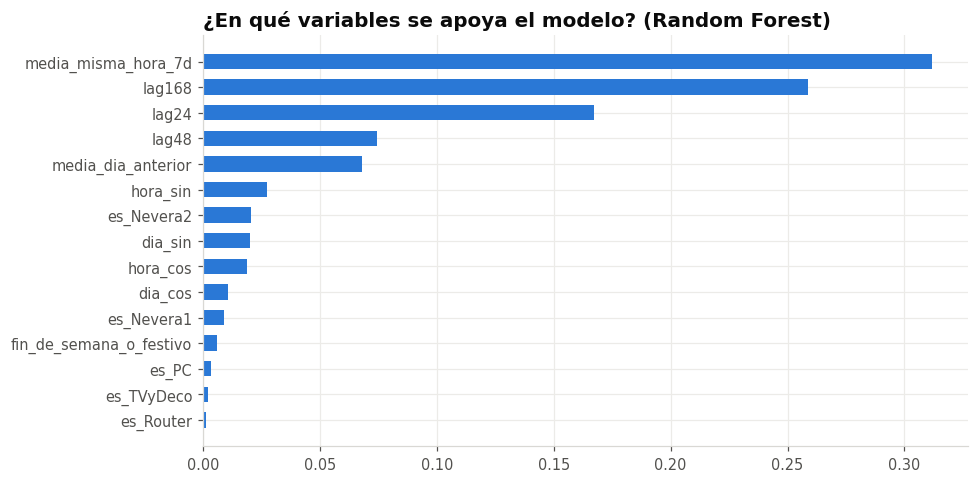

**Predicción de los 7 días siguientes a 27-Oct 00:00:**

aparato,Nevera1,Nevera2,TVyDeco,PC,Router,Total kWh,COP
fecha_hora,,,,,,,
2026-10-27,0.841,1.199,0.632,0.780,0.457,3.909,"3,322.758"
2026-10-28,0.841,1.255,0.623,0.644,0.453,3.817,"3,244.203"
2026-10-29,0.805,1.367,0.625,0.660,0.457,3.914,"3,326.678"
2026-10-30,0.808,1.511,0.610,0.589,0.457,3.974,"3,378.241"
2026-10-31,0.839,1.626,0.736,0.532,0.452,4.185,"3,557.445"
2026-11-01,0.844,1.617,0.736,0.768,0.458,4.423,"3,759.198"
2026-11-02,0.838,1.495,0.665,0.658,0.456,4.111,"3,494.636"


Total semana: 28.33 kWh ≈ $24.083


In [ ]:
modelo_final = sklearn.base.clone(modelos[MEJOR]).fit(datos[VARIABLES_PREDICCION], datos.kwh)

if hasattr(modelo_final, 'feature_importances_'):
    imp = pd.Series(modelo_final.feature_importances_, index=VARIABLES_PREDICCION).sort_values()
else:
    from sklearn.inspection import permutation_importance
    muestra = datos.sample(min(2000, len(datos)), random_state=SEMILLA)
    r = permutation_importance(modelo_final, muestra[VARIABLES_PREDICCION], muestra.kwh, n_repeats=5, random_state=SEMILLA)
    imp = pd.Series(r.importances_mean, index=VARIABLES_PREDICCION).sort_values()
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(imp.index, imp.values, color='#2a78d6', height=0.6)
ax.set_title(f'¿En qué variables se apoya el modelo? ({MEJOR})')
plt.tight_layout(); plt.show()

# Predicción de los próximos 7 días con el modelo final
siguiente = horaria.fecha_hora.max() + pd.Timedelta(hours=1)
semana = prediccion_recursiva(modelo_final, H, siguiente)
tabla_semana = semana.pivot_table(index=semana.fecha_hora.dt.date, columns='aparato', values='kwh_pred', aggfunc='sum')[ORDEN]
tabla_semana['Total kWh'] = tabla_semana.sum(axis=1)
tabla_semana['COP'] = tabla_semana['Total kWh'] * TARIFA_COP_KWH
display(Markdown(f'**Predicción de los 7 días siguientes a {siguiente:%d-%b %H:%M}:**'))
display(tabla_semana.round(3))
print(f'Total semana: {semana.kwh_pred.sum():.2f} kWh ≈ {fmt_cop(semana.kwh_pred.sum() * TARIFA_COP_KWH)}')

## 6. Detección de anomalías (Isolation Forest)
Un Isolation Forest por aparato modela una hora normal a partir de la energía, el porcentaje del tiempo encendido, los arranques, la potencia media encendido y la hora del día. Las horas atípicas reciben un puntaje bajo.

**Umbral:** el puntaje del percentil 1 de las horas de entrenamiento. En operación, una hora con puntaje menor genera una alerta.

,horas,horas anómalas,umbral
aparato,,,
Nevera1,658,6,-0.139
Nevera2,658,7,-0.127
TVyDeco,658,7,-0.154
PC,658,7,-0.150
Router,658,7,-0.185


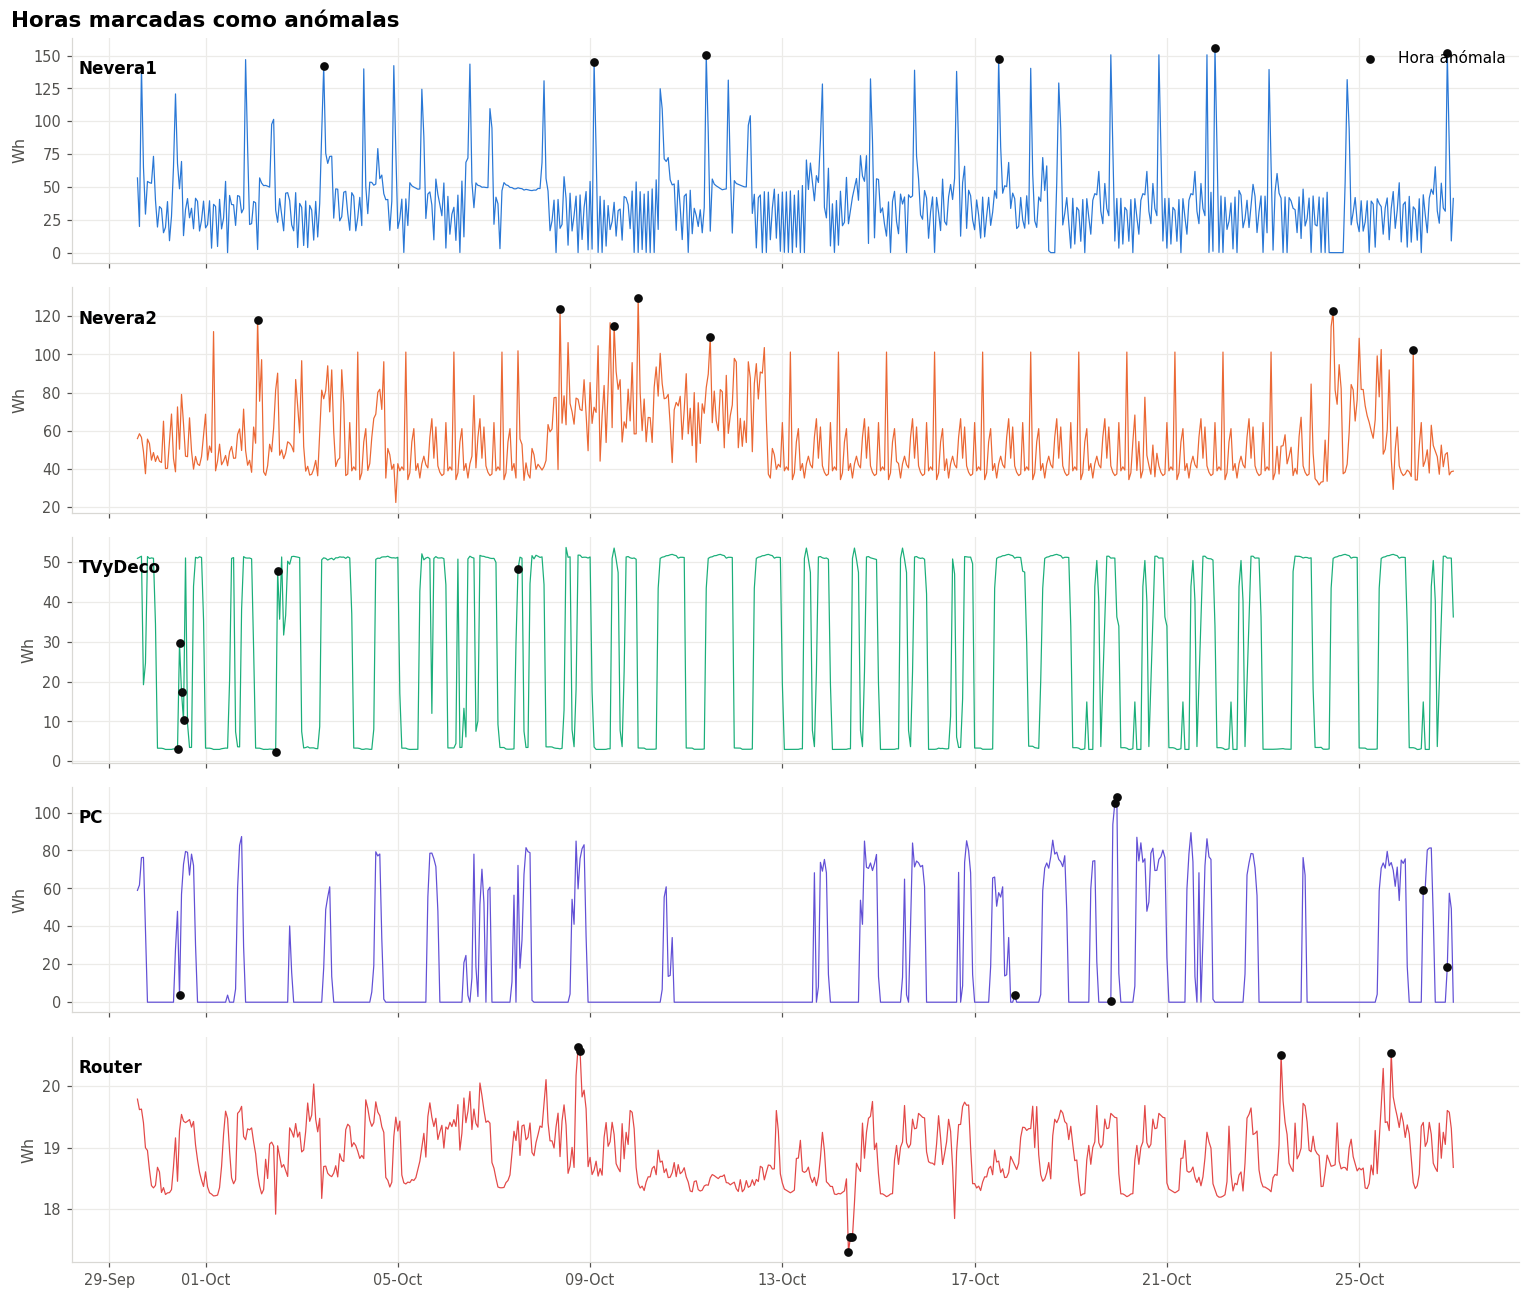

**Las horas más anómalas:**

,fecha_hora,aparato,kwh,pct_encendido,arranques,p_encendido_media,puntaje
2655,2026-09-30 13:00:00,TVyDeco,0.010,16.667,1,50.605,-0.281
2701,2026-10-02 11:00:00,TVyDeco,0.002,11.667,1,2.876,-0.257
2653,2026-09-30 11:00:00,TVyDeco,0.030,98.333,1,30.148,-0.232
2702,2026-10-02 12:00:00,TVyDeco,0.048,98.333,1,48.617,-0.209
2822,2026-10-07 12:00:00,TVyDeco,0.048,98.333,1,49.041,-0.209
2329,2026-10-14 09:00:00,Router,0.017,100.000,0,17.305,-0.209
2545,2026-10-23 09:00:00,Router,0.021,100.000,0,20.502,-0.204
2194,2026-10-08 18:00:00,Router,0.021,100.000,0,20.632,-0.203
2600,2026-10-25 16:00:00,Router,0.021,100.000,0,20.540,-0.201
2654,2026-09-30 12:00:00,TVyDeco,0.017,31.667,0,50.166,-0.198


In [ ]:
from sklearn.ensemble import IsolationForest

PERCENTIL_UMBRAL = 1.0
ha = variables_anomalias(horaria)
detectores, filas = {}, []
for a in ORDEN:
    g = ha[ha.aparato == a].dropna(subset=VARIABLES_ANOMALIAS)
    det = IsolationForest(n_estimators=200, contamination='auto', random_state=SEMILLA).fit(g[VARIABLES_ANOMALIAS])
    puntaje = det.decision_function(g[VARIABLES_ANOMALIAS])
    umbral = float(np.percentile(puntaje, PERCENTIL_UMBRAL))
    detectores[a] = {'modelo': det, 'umbral': umbral}
    ha.loc[g.index, 'puntaje'] = puntaje
    ha.loc[g.index, 'anomalia'] = puntaje < umbral
    filas.append({'aparato': a, 'horas': len(g), 'horas anómalas': int((puntaje < umbral).sum()), 'umbral': umbral})
display(pd.DataFrame(filas).set_index('aparato').round(4))

fig, axes = plt.subplots(len(ORDEN), 1, figsize=(14, 12), sharex=True)
for ax, a in zip(axes, ORDEN):
    g = ha[ha.aparato == a]
    ax.plot(g.fecha_hora, g.kwh * 1000, color=COLOR[a], lw=0.8)
    s = g[g.anomalia == True]
    ax.scatter(s.fecha_hora, s.kwh * 1000, s=22, color=TINTA, zorder=3, label='Hora anómala')
    ax.text(0.005, 0.84, a, transform=ax.transAxes, fontsize=11, fontweight='bold'); ax.set_ylabel('Wh')
axes[0].legend(loc='upper right')
axes[-1].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%d-%b'))
fig.suptitle('Horas marcadas como anómalas', x=0.01, ha='left', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

display(Markdown('**Las horas más anómalas:**'))
display(ha[ha.anomalia == True].nsmallest(10, 'puntaje')[['fecha_hora', 'aparato', 'kwh', 'pct_encendido', 'arranques', 'p_encendido_media', 'puntaje']])

## 7. Exportar los modelos
Se guardan los modelos y el archivo de información en `modelos_EnergIA.zip`. En la Raspberry, su contenido va en la carpeta `modelos/` del backend, con la misma versión de scikit-learn que muestra la celda de Configuración.

In [ ]:
os.makedirs('modelos', exist_ok=True)
joblib.dump(modelo_final, 'modelos/modelo_prediccion.joblib', compress=3)
joblib.dump(detectores, 'modelos/modelo_anomalias.joblib', compress=3)
shutil.copy('variables.py', 'modelos/variables.py')

info = {
    'creado': datetime.now().isoformat(timespec='seconds'),
    'versiones': {'scikit-learn': sklearn.__version__, 'pandas': pd.__version__, 'numpy': np.__version__},
    'datos': {'desde': str(horaria.fecha_hora.min()), 'hasta': str(horaria.fecha_hora.max() + pd.Timedelta(hours=1)),
              'horas': int(horaria.fecha_hora.nunique()), 'aparatos': APARATOS},
    'prediccion': {
        'archivo': 'modelo_prediccion.joblib', 'tipo': MEJOR, 'objetivo': 'kwh por hora y aparato',
        'horizonte_horas': HORIZONTE_HORAS, 'estrategia': 'recursiva por bloques de 24 h',
        'variables': VARIABLES_PREDICCION,
        'evaluacion': {'tipo': 'origen móvil', 'origenes': [f'{o:%Y-%m-%d}' for o in ORIGENES],
                       'semana_prueba': f'{ORIGEN_PRUEBA:%Y-%m-%d}'},
        'metricas': {n: {'MAE_Wh': round(float(resumen_eval.loc[n, 'MAE (Wh)']), 2),
                         'MAPE_semanal_pct': round(float(resumen_eval.loc[n, 'MAPE semanal (%)']), 2),
                         'MAPE_diario_pct': round(float(resumen_eval.loc[n, 'MAPE diario (%)']), 2)}
                     for n in NOMBRES},
        'error_por_dia_horizonte_pct': {n: [round(float(v), 2) for v in por_dia[n]] for n in NOMBRES},
        'metricas_por_aparato': {a: {'MAE_Wh': round(float(por_aparato.loc[a, 'MAE (Wh)']), 2),
                                     'MAPE_semanal_pct': round(float(por_aparato.loc[a, 'MAPE semanal (%)']), 2)}
                                 for a in ORDEN},
    },
    'anomalias': {
        'archivo': 'modelo_anomalias.joblib', 'tipo': 'IsolationForest por aparato',
        'variables': VARIABLES_ANOMALIAS, 'percentil_umbral': PERCENTIL_UMBRAL,
        'umbrales': {a: round(d['umbral'], 6) for a, d in detectores.items()},
    },
    'tarifa_cop_kwh': TARIFA_COP_KWH,
}
with open('modelos/modelos_info.json', 'w', encoding='utf-8') as f:
    json.dump(info, f, indent=2, ensure_ascii=False)

shutil.make_archive('modelos_EnergIA', 'zip', 'modelos')
for nombre in sorted(os.listdir('modelos')):
    print(f'  {nombre:28s} {os.path.getsize(os.path.join("modelos", nombre)) / 1024:8.1f} KB')
print('Listo: modelos_EnergIA.zip')

try:
    from google.colab import files
    files.download('modelos_EnergIA.zip')
except ImportError:
    print('No estás en Colab: el zip quedó en la carpeta actual.')

  modelo_anomalias.joblib        3665.5 KB
  modelo_prediccion.joblib       1784.0 KB
  modelos_info.json                 3.1 KB
  variables.py                      7.0 KB
Listo: modelos_EnergIA.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Resumen

In [ ]:
e = resumen_eval
dias_h = ', '.join(f'{v:.1f}' for v in por_dia[MEJOR])
texto = f"""
**Datos:** {info['datos']['horas']:,} horas de {len(APARATOS)} aparatos, del {horaria.fecha_hora.min():%d-%b-%Y} al {horaria.fecha_hora.max():%d-%b-%Y}.

**Predicción semanal ({MEJOR}, recursiva):** evaluada desde {len(ORIGENES)} orígenes ({ORIGENES[0]:%d-%b} a {ORIGENES[-1]:%d-%b}).
Error medio de {e.loc[MEJOR, 'MAE (Wh)']:.1f} Wh por hora y aparato; {e.loc[MEJOR, 'MAPE semanal (%)']:.1f} % de error en la energía de la casa en la semana
y {e.loc[MEJOR, 'MAPE diario (%)']:.1f} % en la de cada día. Por día de horizonte (1 a 7): {dias_h} %.

Referencias: "semana pasada" {e.loc['Semana pasada', 'MAE (Wh)']:.1f} Wh y {e.loc['Semana pasada', 'MAPE semanal (%)']:.1f} % semanal;
"promedio 7 días" {e.loc['Promedio 7 días', 'MAE (Wh)']:.1f} Wh y {e.loc['Promedio 7 días', 'MAPE semanal (%)']:.1f} % semanal.
Frente a la mejor referencia ({mejor_ref}): {mejora:+.1f} % de error.

**Anomalías:** un Isolation Forest por aparato; el umbral marca como anómalo el {PERCENTIL_UMBRAL:.0f} % de horas más raras del entrenamiento.

**Archivos:** `modelo_prediccion.joblib`, `modelo_anomalias.joblib`, `modelos_info.json` y `variables.py`, en `modelos_EnergIA.zip`.
"""
display(Markdown(texto))


**Datos:** 658 horas de 5 aparatos, del 29-Sep-2026 al 26-Oct-2026.

**Predicción semanal (Random Forest, recursiva):** evaluada desde 7 orígenes (14-Oct a 20-Oct).
Error medio de 14.1 Wh por hora y aparato; 7.8 % de error en la energía de la casa en la semana
y 12.9 % en la de cada día. Por día de horizonte (1 a 7): 7.6, 8.8, 12.3, 14.4, 16.4, 15.2, 15.8 %.

Referencias: "semana pasada" 14.5 Wh y 1.6 % semanal;
"promedio 7 días" 13.3 Wh y 1.6 % semanal.
Frente a la mejor referencia (Promedio 7 días): -6.0 % de error.

**Anomalías:** un Isolation Forest por aparato; el umbral marca como anómalo el 1 % de horas más raras del entrenamiento.

**Archivos:** `modelo_prediccion.joblib`, `modelo_anomalias.joblib`, `modelos_info.json` y `variables.py`, en `modelos_EnergIA.zip`.
